# 06 · Phase 2 Model Validation and Bayesian Tuning

This notebook upgrades the Phase 1 single holdout to group-aware five-fold cross-validation on the 80 training trips, compares all five model families using candidate Macro F1, then tunes the CV winner with Bayesian optimization (Optuna TPE). Student-test trips are used only for development comparison after selection. Evaluator-test trips are intentionally never read here.

In [1]:
from pathlib import Path
import sys,time,json,joblib
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.metrics import f1_score,precision_score,recall_score,log_loss
ROOT=Path.cwd()
if not (ROOT/"src").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
DATA=ROOT/"data"/"Student folder"
RNG_SEED=42
from pathsnap.data import read_trip
from pathsnap.matcher import generate_candidates,FEATURE_NAMES,predict_batch
print("Project:",ROOT,"| train folder:", (DATA/"train").exists(), "| evaluator folder deliberately unused")

Project: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon | train folder: True | evaluator folder deliberately unused


## 1. Build the permitted development data

We build candidates from the 80 labelled training trips and the 10 student-test trips. The evaluator ZIP is not loaded anywhere in this notebook. Each GPS observation yields up to 12 candidate rows with the same five Phase 1 features.

In [2]:
train_trips=[read_trip(p,"train") for p in sorted((DATA/"train").iterdir()) if p.is_dir() and (p/f"{p.name}.track").exists()]
student_trips=[read_trip(p,"student_test") for p in sorted((DATA/"student_test").iterdir()) if p.is_dir() and (p/f"{p.name}.track").exists()]
print("Training trips:",len(train_trips),"student-test trips:",len(student_trips))
t0=time.perf_counter()
train_batches=[(t.trip_id,generate_candidates(t,k=12)) for t in train_trips]
student_batches=[(t.trip_id,generate_candidates(t,k=12)) for t in student_trips]
print("Candidate generation seconds:",round(time.perf_counter()-t0,2))
print("Features:",FEATURE_NAMES,"| sample feature shape:",train_batches[0][1].features.shape)

Training trips: 80 student-test trips: 10


Candidate generation seconds: 3.47
Features: ['distance_m', 'heading_difference_rad', 'along_segment_fraction', 'segment_length_m', 'gps_speed_mps'] | sample feature shape: (1315, 12, 5)


## 2. Create candidate labels and trip groups

A row is positive when that candidate arc matches the nearest reference-route arc for the observation. Other candidate rows are negative. Candidate misses are excluded from fitting because their set contains no positive row. We retain a numeric trip group for every candidate so all observations from a trip stay in the same validation fold.

In [3]:
def flatten_train(batches):
    xs=[];ys=[];groups=[]
    for group,(trip_id,b) in enumerate(batches):
        eligible=(b.truth>=0)&(~b.candidate_miss)
        x=b.features[eligible].reshape(-1,len(FEATURE_NAMES))
        ids=b.ids[eligible].reshape(-1)
        truth=np.repeat(b.truth[eligible],b.ids.shape[1])
        y=(ids==truth).astype(np.int8)
        xs.append(x);ys.append(y);groups.append(np.full(len(y),group,dtype=np.int16))
    return np.concatenate(xs),np.concatenate(ys),np.concatenate(groups)
X,y,groups=flatten_train(train_batches)
print("Eligible candidate rows:",len(y),"positive:",int(y.sum()),"negative:",int((y==0).sum()),"trip groups:",len(np.unique(groups)))

Eligible candidate rows: 2231376 positive: 185948 negative: 2045428 trip groups: 80


## 3. Define consistent metrics and imbalance sampling

**Candidate Macro F1** is the primary cross-validation comparison metric here: it averages F1 for the correct-candidate and alternative-candidate classes. Top-1 checks whether the highest-probability candidate matches the route label for each GPS point. Candidate-row Log Loss checks probability quality. Candidate misses remain in evaluation and lower the achievable scores.

In [4]:
def balanced_rows(y,seed=RNG_SEED,cap=200_000):
    rng=np.random.default_rng(seed);pos=np.flatnonzero(y==1);neg=np.flatnonzero(y==0)
    neg_keep=rng.choice(neg,size=min(len(neg),4*len(pos)),replace=False)
    keep=np.concatenate([pos,neg_keep])
    if len(keep)>cap: keep=rng.choice(keep,size=cap,replace=False)
    return keep

def model_factory(name,params=None):
    p=dict(params or {})
    if name=="Logistic Regression": return make_pipeline(StandardScaler(),LogisticRegression(max_iter=p.get("max_iter",300),C=p.get("C",1.0),class_weight="balanced",random_state=RNG_SEED))
    if name=="KNN": return make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=p.get("n_neighbors",9),weights=p.get("weights","distance"),p=p.get("p",2),n_jobs=-1))
    if name=="Decision Tree": return DecisionTreeClassifier(max_depth=p.get("max_depth",14),min_samples_leaf=p.get("min_samples_leaf",4),ccp_alpha=p.get("ccp_alpha",0.0),class_weight="balanced",random_state=RNG_SEED)
    if name=="Random Forest": return RandomForestClassifier(n_estimators=p.get("n_estimators",80),max_depth=p.get("max_depth",18),min_samples_leaf=p.get("min_samples_leaf",2),max_features=p.get("max_features","sqrt"),class_weight="balanced_subsample",n_jobs=-1,random_state=RNG_SEED)
    if name=="Hist Gradient Boosting": return HistGradientBoostingClassifier(max_iter=p.get("max_iter",100),learning_rate=p.get("learning_rate",.08),max_leaf_nodes=p.get("max_leaf_nodes",15),min_samples_leaf=p.get("min_samples_leaf",20),l2_regularization=p.get("l2_regularization",1.0),random_state=RNG_SEED)
    raise ValueError(name)

MODEL_NAMES=["Logistic Regression","KNN","Decision Tree","Random Forest","Hist Gradient Boosting"]


## 4. Five-fold GroupKFold comparison

Each fold holds out whole training trips. All models use the same folds and candidate rows. The fit sample is balanced using only the fold’s training labels. KNN is capped at 5,000 fit rows to keep its distance-based prediction practical. We record fold Macro F1 and Top-1, plus fitting time.

In [5]:
gkf=GroupKFold(n_splits=5)
folds=list(gkf.split(X,y,groups))
cv_rows=[];cv_fold_details=[];trip_by_id={t.trip_id:t for t in train_trips};batch_by_id=dict(train_batches)
for name in MODEL_NAMES:
    macro_scores=[];top1_scores=[];continuity_scores=[];fit_seconds=[]
    for fold,(tr_idx,va_idx) in enumerate(folds,1):
        fit_idx=tr_idx[balanced_rows(y[tr_idx],RNG_SEED+fold)]
        if name=="KNN" and len(fit_idx)>5000:
            rng=np.random.default_rng(RNG_SEED+fold);pos=fit_idx[y[fit_idx]==1];neg=fit_idx[y[fit_idx]==0]
            fit_idx=np.concatenate([rng.choice(pos,size=min(2500,len(pos)),replace=False),rng.choice(neg,size=min(2500,len(neg)),replace=False)])
        model=model_factory(name);t0=time.perf_counter();model.fit(X[fit_idx],y[fit_idx]);fit_s=time.perf_counter()-t0;fit_seconds.append(fit_s)
        prob=model.predict_proba(X[va_idx])[:,1]
        macro=f1_score(y[va_idx],prob>=.5,average="macro",zero_division=0);macro_scores.append(macro)
        val_group_ids=np.unique(groups[va_idx]);val_trip_ids=[train_batches[int(g)][0] for g in val_group_ids]
        correct=seen=0;trip_cont=[]
        for tid in val_trip_ids:
            b=batch_by_id[tid];n,k=b.ids.shape;pp=model.predict_proba(b.features.reshape(-1,len(FEATURE_NAMES)))[:,1].reshape(n,k)
            pred=b.ids[np.arange(n),np.argmax(pp,axis=1)];ok=b.truth>=0
            correct+=int(np.sum((pred==b.truth)&ok));seen+=int(ok.sum())
            arcs=trip_by_id[tid].arcs
            if len(pred)>1:trip_cont.append(float(np.mean(arcs[pred[:-1],1]==arcs[pred[1:],0])))
        top1=correct/max(seen,1);cont=float(np.mean(trip_cont)) if trip_cont else 0.0
        top1_scores.append(top1);continuity_scores.append(cont)
        cv_fold_details.append({"model":name,"fold":fold,"candidate_macro_f1":macro,"top1_accuracy":top1,"direct_arc_continuity":cont,"fit_seconds":fit_s,"heldout_trips":len(val_trip_ids)})
    cv_rows.append({"model":name,"cv_macro_f1_mean":float(np.mean(macro_scores)),"cv_macro_f1_std":float(np.std(macro_scores,ddof=1)),"cv_top1_mean":float(np.mean(top1_scores)),"cv_top1_std":float(np.std(top1_scores,ddof=1)),"cv_direct_arc_continuity_mean":float(np.mean(continuity_scores)),"mean_fold_fit_seconds":float(np.mean(fit_seconds))})
cv_df=pd.DataFrame(cv_rows).sort_values("cv_macro_f1_mean",ascending=False).reset_index(drop=True)
display(cv_df.round(4))
pd.DataFrame(cv_fold_details).to_csv(ROOT/"outputs"/"phase2_cv_folds.csv",index=False)
cv_df.to_csv(ROOT/"outputs"/"phase2_cv_model_comparison.csv",index=False)

,model,cv_macro_f1_mean,cv_macro_f1_std,cv_top1_mean,cv_top1_std,cv_direct_arc_continuity_mean,mean_fold_fit_seconds
0,Hist Gradient Boosting,0.8485,0.0251,0.6787,0.1381,0.2751,0.6303
1,Random Forest,0.8327,0.0183,0.6847,0.1258,0.2744,2.3150
2,Decision Tree,0.7981,0.0143,0.6576,0.1310,0.2712,0.5641
3,KNN,0.7202,0.0188,0.5953,0.1169,0.2531,0.0023
4,Logistic Regression,0.6358,0.0382,0.5023,0.0484,0.2425,0.0524


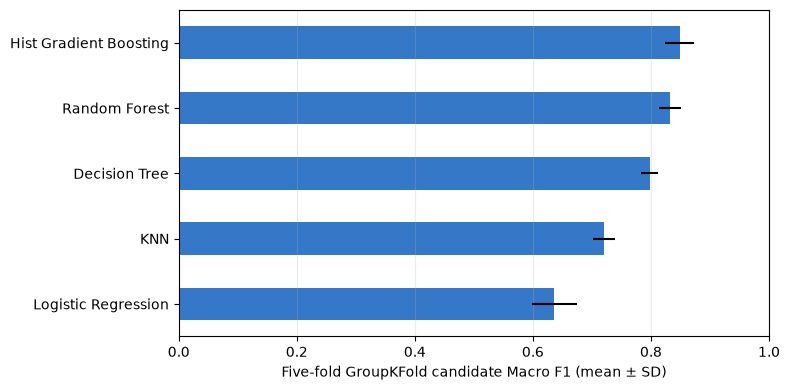

In [6]:
ax=cv_df.sort_values("cv_macro_f1_mean").plot.barh(x="model",y="cv_macro_f1_mean",xerr="cv_macro_f1_std",legend=False,figsize=(8,4),color="#3478c7")
ax.set_xlabel("Five-fold GroupKFold candidate Macro F1 (mean ± SD)");ax.set_ylabel("");ax.set_xlim(0,1);ax.grid(axis="x",alpha=.25);plt.tight_layout()

## 5. Select the CV winner, then compare on student-test

The best initial model is selected by mean five-fold candidate Macro F1, not by the student-test score. We then refit every model on the 80 training trips and report student-test metrics as a development comparison. The student partition is never used in the Optuna objective.

In [7]:
def score_batches(model,batches,trip_lookup):
    all_y=[];all_p=[];correct=total=miss=0;elapsed=0.0;continuities=[]
    for tid,b in batches:
        n,k=b.ids.shape;t0=time.perf_counter();p=model.predict_proba(b.features.reshape(-1,len(FEATURE_NAMES)))[:,1].reshape(n,k);elapsed+=time.perf_counter()-t0
        valid=b.truth>=0;pred=b.ids[np.arange(n),np.argmax(p,axis=1)]
        correct+=int(np.sum((pred==b.truth)&valid));total+=int(valid.sum());miss+=int(np.sum(b.candidate_miss&valid))
        all_y.append((b.ids[valid].reshape(-1)==np.repeat(b.truth[valid],k)).astype(np.int8));all_p.append(p[valid].reshape(-1))
        arcs=trip_lookup[tid].arcs
        if n>1:continuities.append(float(np.mean(arcs[pred[:-1],1]==arcs[pred[1:],0])))
    yy=np.concatenate(all_y);pp=np.concatenate(all_p);hard=pp>=.5
    return {"top1_accuracy":correct/max(total,1),"candidate_macro_f1":f1_score(yy,hard,average="macro",zero_division=0),"candidate_precision":precision_score(yy,hard,zero_division=0),"candidate_recall":recall_score(yy,hard,zero_division=0),"candidate_log_loss":log_loss(yy,np.clip(pp,1e-6,1-1e-6),labels=[0,1]),"candidate_miss_rate":miss/max(total,1),"direct_arc_continuity_trip_mean":float(np.mean(continuities)),"inference_seconds":elapsed,"observations":total}

student_lookup={t.trip_id:t for t in student_trips}
student_rows=[];all_fit_models={};fit_arrays={}
for name in MODEL_NAMES:
    model=model_factory(name);fit_idx=balanced_rows(y,RNG_SEED)
    if name=="KNN" and len(fit_idx)>5000:
        rng=np.random.default_rng(RNG_SEED);pos=fit_idx[y[fit_idx]==1];neg=fit_idx[y[fit_idx]==0]
        fit_idx=np.concatenate([rng.choice(pos,size=min(2500,len(pos)),replace=False),rng.choice(neg,size=min(2500,len(neg)),replace=False)])
    t0=time.perf_counter();model.fit(X[fit_idx],y[fit_idx]);fit_s=time.perf_counter()-t0
    m=score_batches(model,student_batches,student_lookup);student_rows.append({"model":name,"training_seconds":fit_s,**{f"student_{k}":v for k,v in m.items()}})
    all_fit_models[name]=model;fit_arrays[name]=fit_idx
student_df=pd.DataFrame(student_rows);display(student_df[["model","training_seconds","student_top1_accuracy","student_candidate_macro_f1","student_candidate_precision","student_candidate_recall","student_candidate_log_loss","student_direct_arc_continuity_trip_mean","student_inference_seconds"]].round(4))
student_df.to_csv(ROOT/"outputs"/"phase2_student_comparison.csv",index=False)
selected_name=cv_df.iloc[0].model
print("Selected by 5-fold CV candidate Macro F1:",selected_name)

,model,training_seconds,student_top1_accuracy,student_candidate_macro_f1,student_candidate_precision,student_candidate_recall,student_candidate_log_loss,student_direct_arc_continuity_trip_mean,student_inference_seconds
0,Logistic Regression,0.0596,0.5780,0.6088,0.2311,0.9143,0.4637,0.2197,0.0046
1,KNN,0.0016,0.6611,0.7233,0.3639,0.9320,0.5437,0.2387,0.4632
2,Decision Tree,0.5709,0.7332,0.7980,0.4881,0.9385,0.2287,0.2521,0.0070
3,Random Forest,2.3557,0.7523,0.8413,0.5848,0.9181,0.1400,0.2552,0.1939
4,Hist Gradient Boosting,0.6791,0.7544,0.8613,0.6547,0.8720,0.1067,0.2539,0.1418


Selected by 5-fold CV candidate Macro F1: Hist Gradient Boosting


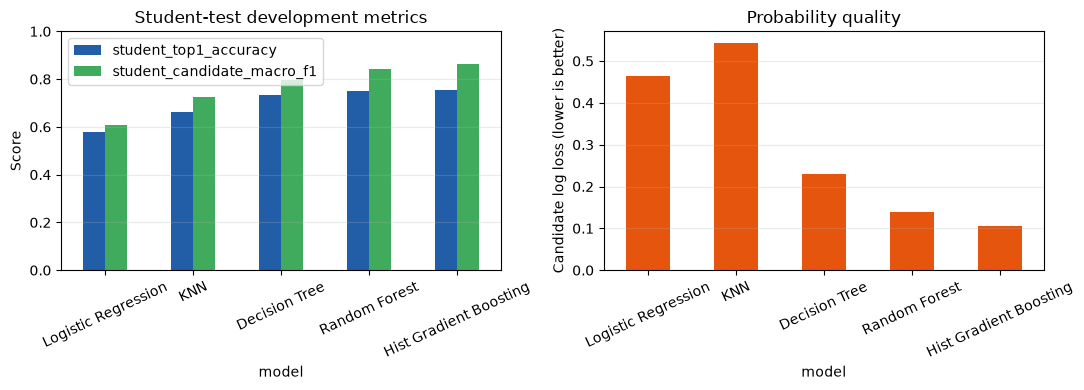

In [8]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
student_df.set_index("model")[["student_top1_accuracy","student_candidate_macro_f1"]].plot.bar(ax=axs[0],color=["#225ea8","#41ab5d"])
axs[0].set_ylim(0,1);axs[0].set_ylabel("Score");axs[0].set_title("Student-test development metrics");axs[0].tick_params(axis="x",rotation=25);axs[0].grid(axis="y",alpha=.25)
student_df.set_index("model")["student_candidate_log_loss"].plot.bar(ax=axs[1],color="#e6550d")
axs[1].set_ylabel("Candidate log loss (lower is better)");axs[1].set_title("Probability quality");axs[1].tick_params(axis="x",rotation=25);axs[1].grid(axis="y",alpha=.25)
fig.tight_layout()

## 6. Bayesian hyperparameter optimisation with Optuna TPE

We tune only the CV-selected model. Optuna’s Tree-structured Parzen Estimator (TPE) uses earlier trials to choose promising next settings. The objective is mean candidate Macro F1 across the same five group-aware training folds. Evaluator trips are not loaded; student-test scores do not enter the objective.

In [9]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
def suggest_params(trial,name):
    if name=="Logistic Regression": return {"C":trial.suggest_float("C",1e-3,100,log=True),"max_iter":400}
    if name=="KNN": return {"n_neighbors":trial.suggest_int("n_neighbors",3,25,step=2),"weights":trial.suggest_categorical("weights",["uniform","distance"]),"p":trial.suggest_int("p",1,2)}
    if name=="Decision Tree": return {"max_depth":trial.suggest_int("max_depth",5,30),"min_samples_leaf":trial.suggest_int("min_samples_leaf",1,20),"ccp_alpha":trial.suggest_float("ccp_alpha",1e-6,.02,log=True)}
    if name=="Random Forest": return {"n_estimators":trial.suggest_int("n_estimators",60,220,step=20),"max_depth":trial.suggest_int("max_depth",8,30),"min_samples_leaf":trial.suggest_int("min_samples_leaf",1,10),"max_features":trial.suggest_categorical("max_features",["sqrt",.7,1.0])}
    return {"max_iter":trial.suggest_int("max_iter",60,240,step=20),"learning_rate":trial.suggest_float("learning_rate",.025,.2,log=True),"max_leaf_nodes":trial.suggest_int("max_leaf_nodes",7,31),"min_samples_leaf":trial.suggest_int("min_samples_leaf",10,60),"l2_regularization":trial.suggest_float("l2_regularization",1e-4,10,log=True)}

def objective(trial):
    params=suggest_params(trial,selected_name);fold_scores=[]
    for fold,(tr_idx,va_idx) in enumerate(folds,1):
        fit_idx=tr_idx[balanced_rows(y[tr_idx],RNG_SEED+fold)]
        if selected_name=="KNN" and len(fit_idx)>5000:
            rng=np.random.default_rng(RNG_SEED+fold);pos=fit_idx[y[fit_idx]==1];neg=fit_idx[y[fit_idx]==0]
            fit_idx=np.concatenate([rng.choice(pos,size=min(2500,len(pos)),replace=False),rng.choice(neg,size=min(2500,len(neg)),replace=False)])
        m=model_factory(selected_name,params);m.fit(X[fit_idx],y[fit_idx])
        prob=m.predict_proba(X[va_idx])[:,1]
        fold_scores.append(f1_score(y[va_idx],prob>=.5,average="macro",zero_division=0))
    trial.set_user_attr("fold_scores",fold_scores)
    return float(np.mean(fold_scores))
study=optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=RNG_SEED))
tune_start=time.perf_counter();study.optimize(objective,n_trials=15,show_progress_bar=False);tuning_seconds=time.perf_counter()-tune_start
trials_df=study.trials_dataframe(attrs=("number","value","params","state"));trials_df.to_csv(ROOT/"outputs"/"phase2_bayesian_trials.csv",index=False)
print("Tuned model:",selected_name,"trials:",len(study.trials),"best CV Macro F1:",round(study.best_value,4),"seconds:",round(tuning_seconds,1))
print("Best settings:",study.best_params)
display(trials_df.sort_values("value",ascending=False).head(10))

/Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tuned model: Hist Gradient Boosting trials: 15 best CV Macro F1: 0.8516 seconds: 55.1
Best settings: {'max_iter': 60, 'learning_rate': 0.025906929241559098, 'max_leaf_nodes': 31, 'min_samples_leaf': 47, 'l2_regularization': 0.04872726908082339}


,number,value,params_l2_regularization,params_learning_rate,params_max_iter,params_max_leaf_nodes,params_min_samples_leaf,state
12,12,0.851581,0.048727,0.025907,60,31,47,COMPLETE
14,14,0.850141,1.184009,0.033385,60,26,56,COMPLETE
13,13,0.849810,0.382464,0.031099,80,31,43,COMPLETE
1,1,0.849808,0.347027,0.028209,80,28,40,COMPLETE
11,11,0.849037,0.052572,0.042413,180,28,43,COMPLETE
9,9,0.848749,0.000840,0.047802,180,20,37,COMPLETE
10,10,0.848727,1.005498,0.049815,60,25,21,COMPLETE
5,5,0.848575,0.000171,0.037867,200,19,40,COMPLETE
4,4,0.848400,0.019070,0.033413,180,14,28,COMPLETE
7,7,0.848354,0.015877,0.047101,220,9,44,COMPLETE


## 7. Compare untuned and tuned CV estimates, then test on student data

The student-test partition is opened only after the model family and search parameters are selected using training-trip CV. This comparison shows whether tuning improved the CV objective and how both frozen configurations perform on the permitted development partition.

In [10]:
# Re-evaluate the untuned CV winner and tuned winner over identical folds.
def cv_summary(name,params=None):
    scores=[];tops=[]
    for fold,(tr_idx,va_idx) in enumerate(folds,1):
        fit_idx=tr_idx[balanced_rows(y[tr_idx],RNG_SEED+fold)]
        if name=="KNN" and len(fit_idx)>5000:
            rng=np.random.default_rng(RNG_SEED+fold);pos=fit_idx[y[fit_idx]==1];neg=fit_idx[y[fit_idx]==0]
            fit_idx=np.concatenate([rng.choice(pos,size=min(2500,len(pos)),replace=False),rng.choice(neg,size=min(2500,len(neg)),replace=False)])
        m=model_factory(name,params);m.fit(X[fit_idx],y[fit_idx]);prob=m.predict_proba(X[va_idx])[:,1]
        scores.append(f1_score(y[va_idx],prob>=.5,average="macro",zero_division=0))
    return float(np.mean(scores)),float(np.std(scores,ddof=1))
untuned_cv_mean,untuned_cv_sd=cv_summary(selected_name)
tuned_cv_mean,tuned_cv_sd=cv_summary(selected_name,study.best_params)
# Student metrics are a report-out only; they do not change selected parameters.
untuned=all_fit_models[selected_name]; tuned=model_factory(selected_name,study.best_params)
fit_idx=balanced_rows(y,RNG_SEED)
if selected_name=="KNN" and len(fit_idx)>5000:
    rng=np.random.default_rng(RNG_SEED);pos=fit_idx[y[fit_idx]==1];neg=fit_idx[y[fit_idx]==0]
    fit_idx=np.concatenate([rng.choice(pos,size=min(2500,len(pos)),replace=False),rng.choice(neg,size=min(2500,len(neg)),replace=False)])
t0=time.perf_counter();tuned.fit(X[fit_idx],y[fit_idx]);tuned_fit_s=time.perf_counter()-t0
untuned_student=score_batches(untuned,student_batches,student_lookup);tuned_student=score_batches(tuned,student_batches,student_lookup)
tuned_comparison=pd.DataFrame([
 {"configuration":"untuned CV winner","cv_macro_f1_mean":untuned_cv_mean,"cv_macro_f1_std":untuned_cv_sd,**{f"student_{k}":v for k,v in untuned_student.items()}},
 {"configuration":"Bayesian tuned","cv_macro_f1_mean":tuned_cv_mean,"cv_macro_f1_std":tuned_cv_sd,"training_seconds":tuned_fit_s,**{f"student_{k}":v for k,v in tuned_student.items()}}])
display(tuned_comparison.round(4));tuned_comparison.to_csv(ROOT/"outputs"/"phase2_tuned_comparison.csv",index=False)

,configuration,cv_macro_f1_mean,cv_macro_f1_std,student_top1_accuracy,student_candidate_macro_f1,student_candidate_precision,student_candidate_recall,student_candidate_log_loss,student_candidate_miss_rate,student_direct_arc_continuity_trip_mean,student_inference_seconds,student_observations,training_seconds
0,untuned CV winner,0.8485,0.0251,0.7544,0.8613,0.6547,0.8720,0.1067,0.0635,0.2539,0.1049,19160,NaN
1,Bayesian tuned,0.8516,0.0279,0.7540,0.8667,0.6914,0.8348,0.1352,0.0635,0.2569,0.0747,19160,0.4214


## 8. Refit the frozen tuned model on all 80 training trips

After completing the permitted development comparison, fit the selected configuration on all training-trip candidate rows and save the final model bundle. This artifact is used by the evaluator API. The evaluator dataset is not used to train, tune, select features, or set thresholds.

In [11]:
# Rebuild a balanced all-training fit sample, then cap for tractable local inference.
all_fit=balanced_rows(y,RNG_SEED,cap=200_000)
if selected_name=="KNN" and len(all_fit)>5000:
    rng=np.random.default_rng(RNG_SEED);pos=all_fit[y[all_fit]==1];neg=all_fit[y[all_fit]==0]
    all_fit=np.concatenate([rng.choice(pos,size=min(2500,len(pos)),replace=False),rng.choice(neg,size=min(2500,len(neg)),replace=False)])
final_model=model_factory(selected_name,study.best_params);final_model.fit(X[all_fit],y[all_fit])
bundle={"model":final_model,"model_name":selected_name,"model_stage":"phase2_bayesian_tuned","feature_names":FEATURE_NAMES,"candidate_k":12,"seed":RNG_SEED,"hyperparameters":study.best_params,"selection_metric":"5-fold GroupKFold candidate Macro F1","cv_macro_f1_mean":tuned_cv_mean,"evaluator_labels_used_for_selection":False}
joblib.dump(bundle,ROOT/"outputs"/"phase2_model.joblib")
print("Saved frozen Phase 2 model:",selected_name,"|",ROOT/"outputs"/"phase2_model.joblib")

Saved frozen Phase 2 model: Hist Gradient Boosting | /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon/outputs/phase2_model.joblib


## 9. What this experiment establishes

The five-fold grouped comparison provides a more reliable training-only model estimate than the Phase 1 single split. Bayesian tuning optimizes candidate Macro F1 on those same permitted training trips. Student-test scores are a separate development comparison. Final evaluator performance will be calculated by the server only after this model is frozen; evaluator routes must not feed back into model selection.